This notebook takes Medellín's OSMNX road network and performs persistent homologgy based on the number of lanes that each street has, making the roads with more lanes the most important, thus the first that appear in the filtration

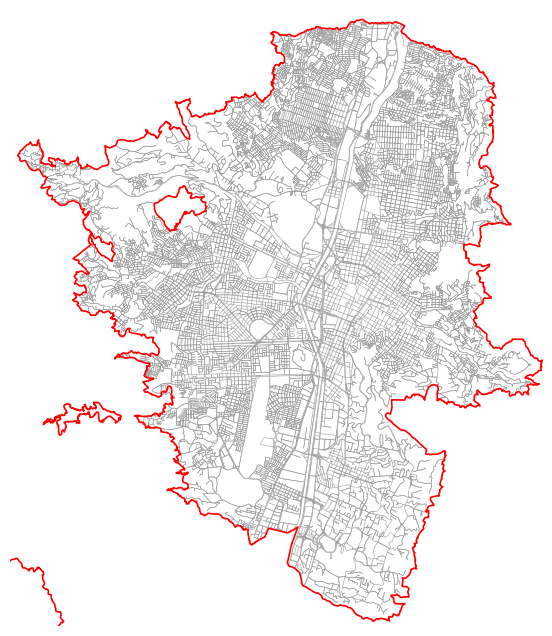

In [6]:
import geopandas as gpd
import osmnx as ox
import matplotlib.pyplot as plt
from pathlib import Path

def find_repo_root(start=Path.cwd()) -> Path:
    for candidate in [start.resolve(), *start.resolve().parents]:
        if (candidate / "edge_importance_ph").exists():
            return candidate
    raise FileNotFoundError(f"Could not find urban_form repository from {start.resolve()}")

REPO_ROOT = find_repo_root()
EDGE_IMPORTANCE_ROOT = REPO_ROOT / "edge_importance_ph"
ROAD_IMPORTANCE_DIR = EDGE_IMPORTANCE_ROOT / "calculate_road_importance"
MDE_FIGS_DIR = EDGE_IMPORTANCE_ROOT / "mde_road_importance_figs"
MDE_FIGS_DIR.mkdir(parents=True, exist_ok=True)

# Ruta al geojson del perímetro urbano
geojson_path = EDGE_IMPORTANCE_ROOT / "corcoran_replication" / "medellin_urban_perimeter" / "query.geojson"

# Leer el geojson
gdf = gpd.read_file(geojson_path)

# Revisar CRS y convertir a WGS84 si es necesario (OSMnx trabaja bien con EPSG:4326)
if gdf.crs is None:
    raise ValueError("El GeoJSON no tiene CRS definido. Asígnalo antes de continuar.")
if gdf.crs.to_epsg() != 4326:
    gdf = gdf.to_crs(epsg=4326)

# Unir todos los polígonos en una sola geometría
urban_geom = gdf.union_all()

# Descargar la red vial únicamente dentro del perímetro urbano
G = ox.graph_from_polygon(
    urban_geom,
    network_type="drive",
    simplify=True
)

# Graficar
fig, ax = ox.plot_graph(
    G,
    node_size=0,
    edge_linewidth=0.4,
    bgcolor="white",
    show=False,
    close=False
)

# Dibujar también el perímetro urbano encima
gpd.GeoSeries([urban_geom], crs="EPSG:4326").boundary.plot(
    ax=ax,
    color="red",
    linewidth=1.2
)

plt.show()

In [7]:
import pandas as pd
import osmnx as ox

# Pasar aristas a GeoDataFrame
edges = ox.graph_to_gdfs(G, nodes=False)

# Ver si existe la columna lanes
print("¿Existe 'lanes'?:", "lanes" in edges.columns)

# Mostrar algunas filas donde sí haya dato
if "lanes" in edges.columns:
    print(edges[["highway", "name", "lanes"]].dropna(subset=["lanes"]).head(20))
else:
    print("No existe la columna 'lanes' en este grafo.")

¿Existe 'lanes'?: True
                              highway                   name   lanes
u         v          key                                            
309026271 404910004  0      secondary               Calle 10       3
309026273 393988726  0      secondary               Calle 10       3
          338171294  0        primary            Carrera 43A       3
309026274 416048073  0      secondary               Calle 10       3
          416048719  0    residential  [Calle 9, Carrera 41]       1
309026275 309026276  0      secondary               Calle 10       3
309026276 309026277  0      secondary               Calle 10       3
309026277 3326866978 0       tertiary             Carrera 36       2
          416130698  0      secondary               Calle 10       3
309026943 313797071  0    residential                Calle 7       2
309026951 309026943  0    residential                Calle 7       2
          393991040  0        primary            Carrera 43A  [2, 3]
309027094 3

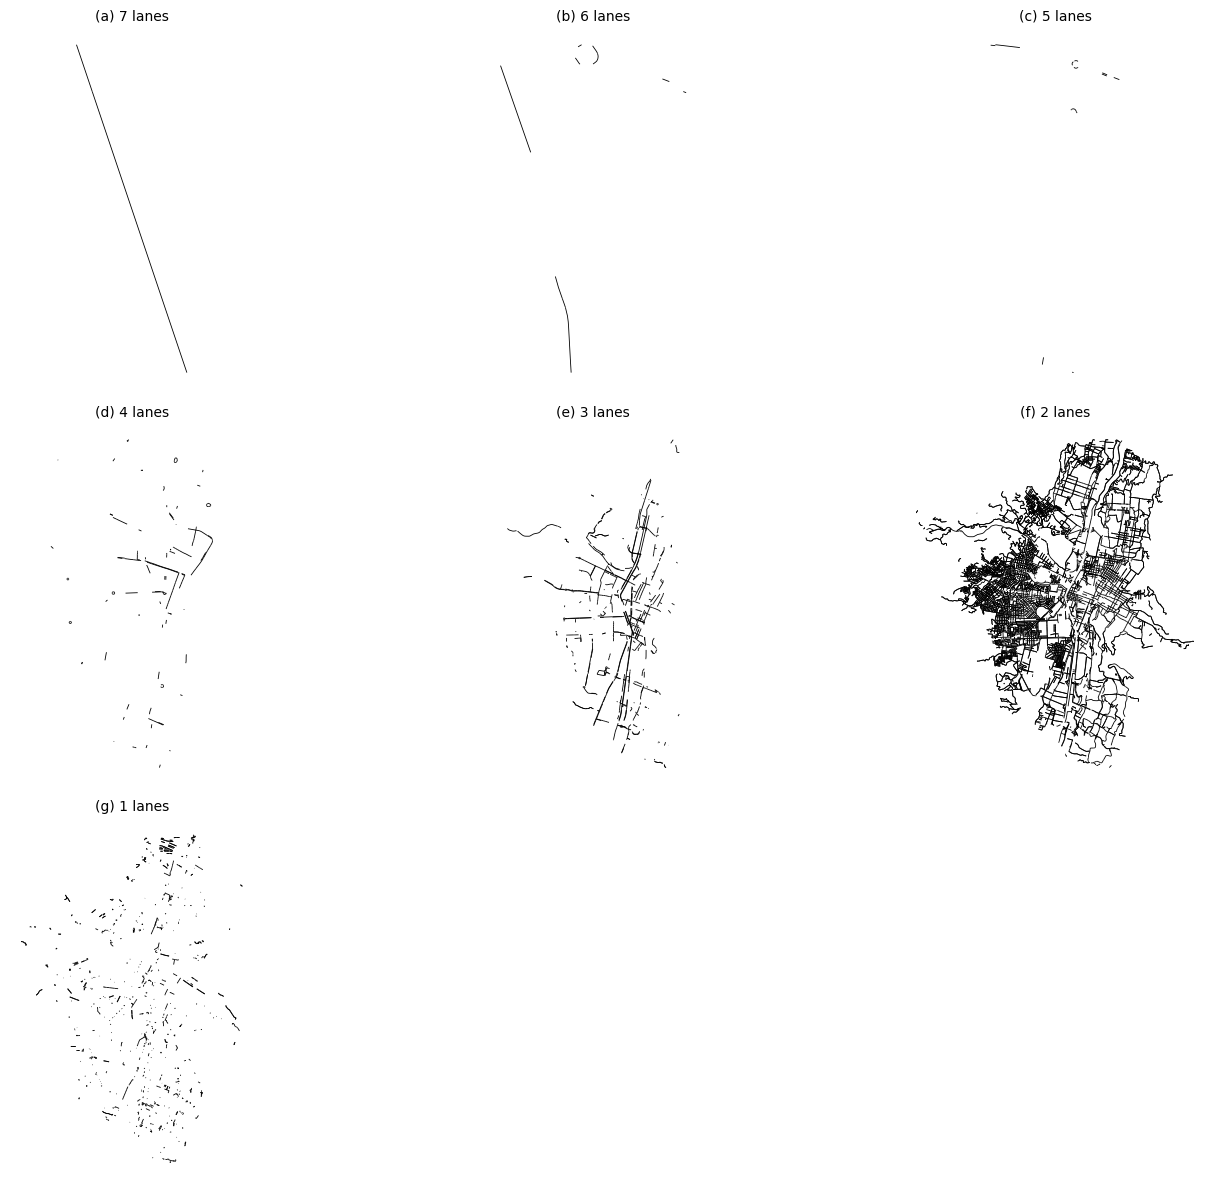

In [8]:
import geopandas as gpd
import osmnx as ox
import matplotlib.pyplot as plt
import numpy as np
import re


def parse_lanes_value(value):
    if value is None:
        return np.nan
    if isinstance(value, (list, tuple, set)):
        parsed = [parse_lanes_value(v) for v in value]
        parsed = [v for v in parsed if np.isfinite(v)]
        return max(parsed) if parsed else np.nan
    if isinstance(value, (int, np.integer)):
        return int(value)
    if isinstance(value, (float, np.floating)):
        return int(value) if np.isfinite(value) else np.nan
    if isinstance(value, str):
        tokens = re.findall(r"\d+", value)
        if not tokens:
            return np.nan
        return max(int(t) for t in tokens)
    return np.nan


# Convert to GeoDataFrame (edges only)
edges = ox.graph_to_gdfs(G, nodes=False).copy()

if "lanes" not in edges.columns:
    raise ValueError("No existe la columna 'lanes' en este grafo.")

edges["lanes_numeric"] = edges["lanes"].apply(parse_lanes_value)
edges = edges[np.isfinite(edges["lanes_numeric"])].copy()
edges["lanes_numeric"] = edges["lanes_numeric"].astype(int)
edges = edges[edges["lanes_numeric"] >= 1].copy()

if edges.empty:
    raise ValueError("No hay aristas con valores de 'lanes' validos (>=1).")

max_lanes = int(edges["lanes_numeric"].max())
lane_order = list(range(max_lanes, 0, -1))

# -----------------------------
# 3. PLOT EACH LANE COUNT
# -----------------------------
n = len(lane_order)
cols = 3
rows = int(np.ceil(n / cols))

fig, axes = plt.subplots(rows, cols, figsize=(14, 4 * rows))
axes = np.atleast_1d(axes).flatten()

for i, lane_count in enumerate(lane_order):
    ax = axes[i]

    subset = edges[edges["lanes_numeric"] == lane_count]

    if not subset.empty:
        subset.plot(
            ax=ax,
            linewidth=0.6,
            color="black",
        )

    ax.set_title(f"({chr(97+i)}) {lane_count} lanes", fontsize=10)
    ax.set_axis_off()

# Remove extra axes if any
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()


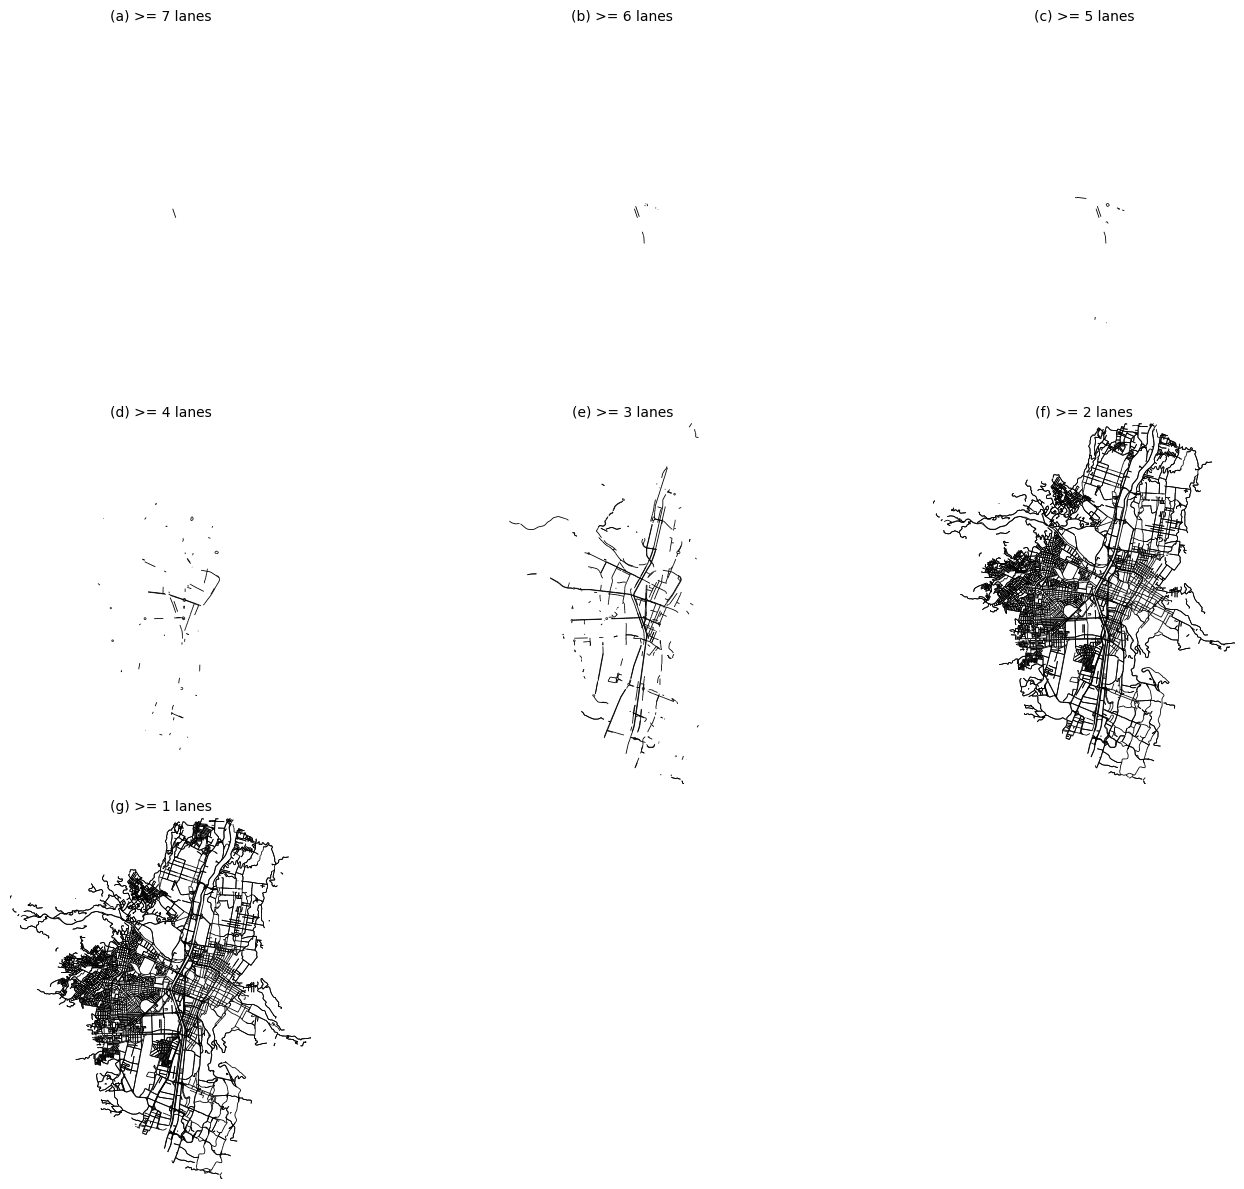

In [9]:
import numpy as np
import osmnx as ox

edges = ox.graph_to_gdfs(G, nodes=False).copy()

if "parse_lanes_value" not in globals():
    import re

    def parse_lanes_value(value):
        if value is None:
            return np.nan
        if isinstance(value, (list, tuple, set)):
            parsed = [parse_lanes_value(v) for v in value]
            parsed = [v for v in parsed if np.isfinite(v)]
            return max(parsed) if parsed else np.nan
        if isinstance(value, (int, np.integer)):
            return int(value)
        if isinstance(value, (float, np.floating)):
            return int(value) if np.isfinite(value) else np.nan
        if isinstance(value, str):
            tokens = re.findall(r"\d+", value)
            if not tokens:
                return np.nan
            return max(int(t) for t in tokens)
        return np.nan

if "lanes" not in edges.columns:
    raise ValueError("No existe la columna 'lanes' en este grafo.")

edges["lanes_numeric"] = edges["lanes"].apply(parse_lanes_value)
edges = edges[np.isfinite(edges["lanes_numeric"])].copy()
edges["lanes_numeric"] = edges["lanes_numeric"].astype(int)
edges = edges[edges["lanes_numeric"] >= 1].copy()

if edges.empty:
    raise ValueError("No hay aristas con valores de 'lanes' validos (>=1).")

max_lanes = int(edges["lanes_numeric"].max())
lane_order = list(range(max_lanes, 0, -1))

# Fix global bounding box so all subplots match
xmin, ymin, xmax, ymax = edges.total_bounds

# -----------------------------
# PLOTTING
# -----------------------------
n = len(lane_order)
cols = 3
rows = int(np.ceil(n / cols))

fig, axes = plt.subplots(rows, cols, figsize=(14, 4 * rows))
axes = np.atleast_1d(axes).flatten()

for i, lane_count in enumerate(lane_order):
    ax = axes[i]

    subset = edges[edges["lanes_numeric"] >= lane_count]

    if not subset.empty:
        subset.plot(
            ax=ax,
            linewidth=0.6,
            color="black",
        )

    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_title(f"({chr(97+i)}) >= {lane_count} lanes", fontsize=10)
    ax.set_axis_off()

# Hide unused axes
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()


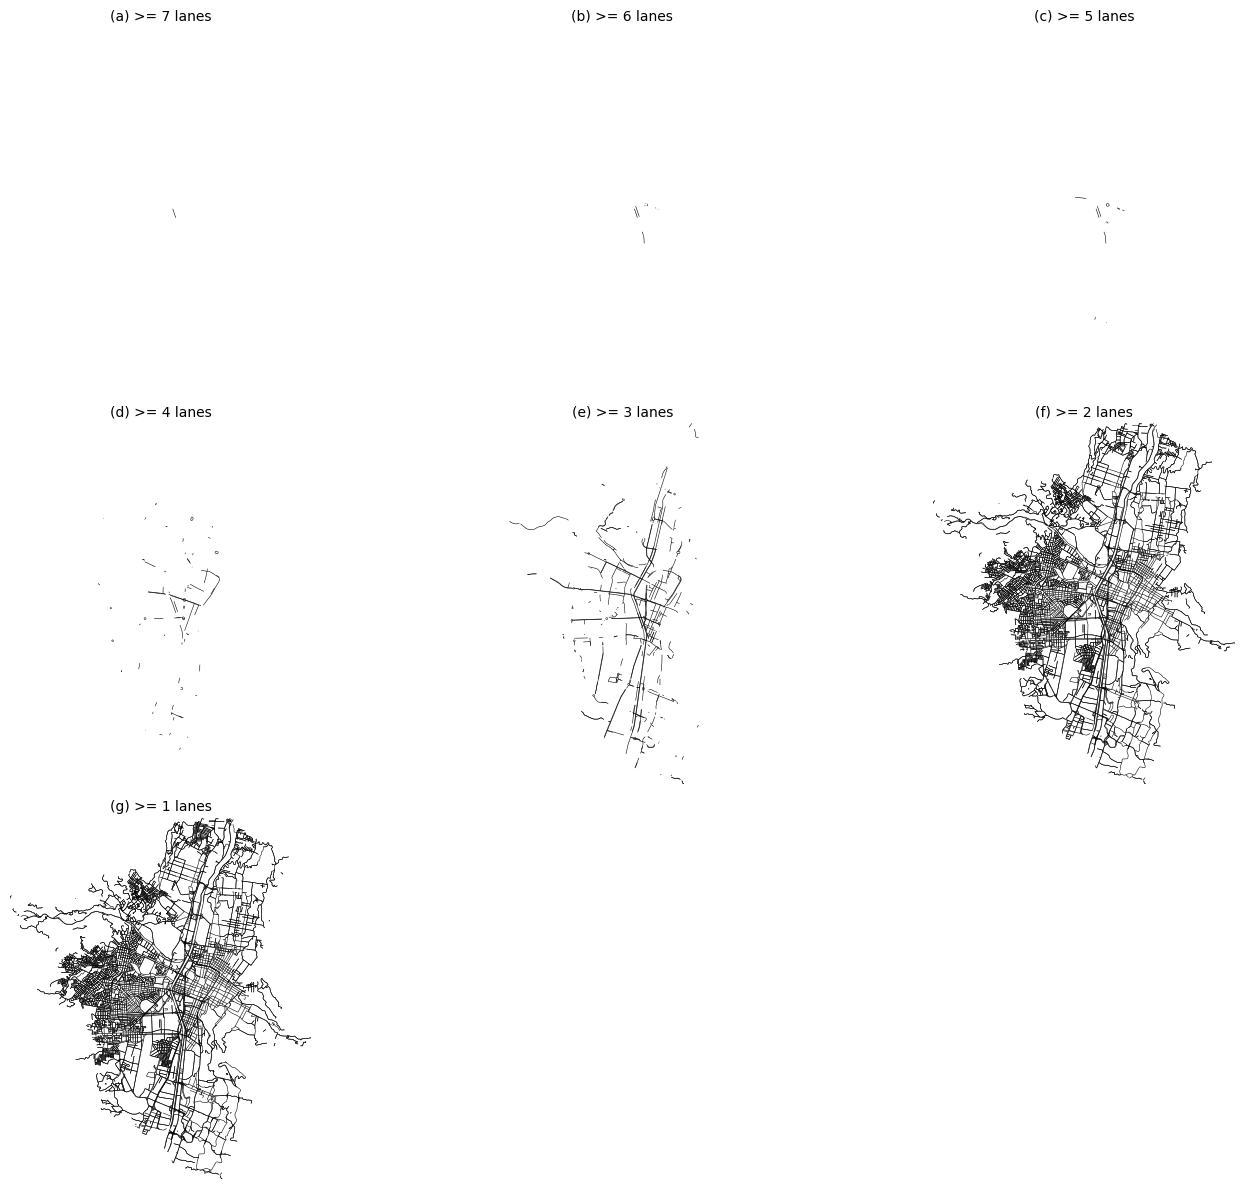

Final graph summary
Nodes: 9723
Edges: 13288

Simplex tree summary
Dimension: 1
Num vertices: 9723
Num simplices: 23011

Finite H1 intervals:
[]

Graph-theoretic diagnostics
Connected components: 52
Cycle rank: 3617

Betti numbers:
[52, 3617]


/opt/homebrew/anaconda3/envs/kernels/lib/python3.10/site-packages/gudhi/persistence_graphical_tools.py:129: UserWarning: usetex mode requires TeX.
  warnings.warn("usetex mode requires TeX.")


<Figure size 700x600 with 0 Axes>

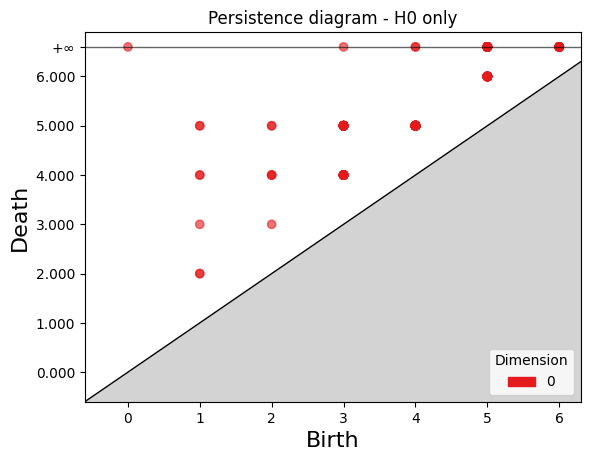

<Figure size 1000x400 with 0 Axes>

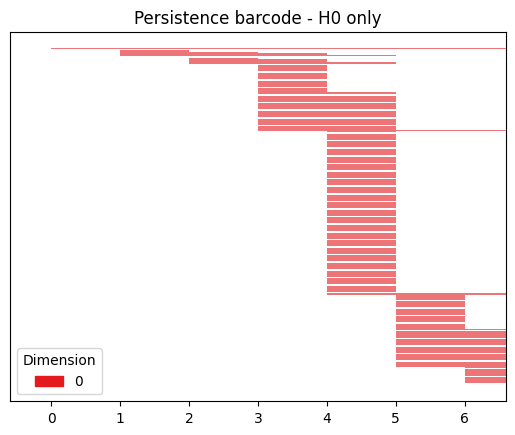

<Figure size 700x600 with 0 Axes>

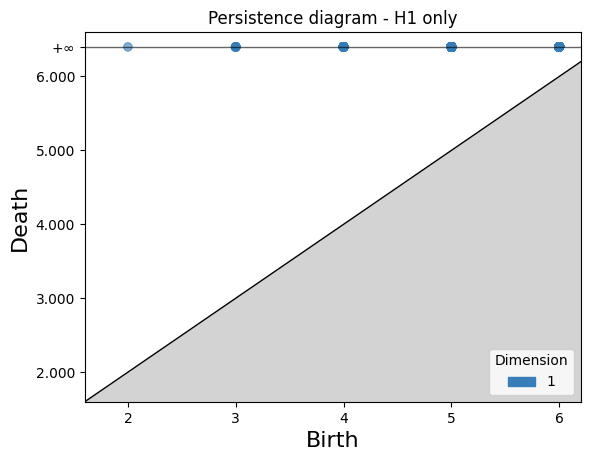

<Figure size 1000x400 with 0 Axes>

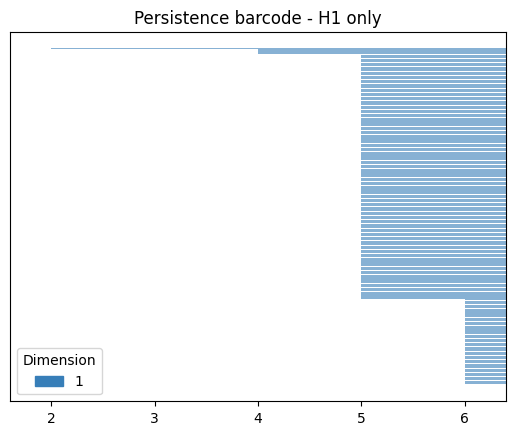


Step-by-step filtration summary

Step 0 -> lanes >= 7
Nodes: 3
Edges: 2
Connected components: 1
Cycle rank: 0

Step 1 -> lanes >= 6
Nodes: 21
Edges: 13
Connected components: 8
Cycle rank: 0

Step 2 -> lanes >= 5
Nodes: 39
Edges: 28
Connected components: 12
Cycle rank: 1

Step 3 -> lanes >= 4
Nodes: 297
Edges: 238
Connected components: 68
Cycle rank: 9

Step 4 -> lanes >= 3
Nodes: 1608
Edges: 1484
Connected components: 181
Cycle rank: 57

Step 5 -> lanes >= 2
Nodes: 9295
Edges: 11928
Connected components: 67
Cycle rank: 2700

Step 6 -> lanes >= 1
Nodes: 9723
Edges: 13288
Connected components: 52
Cycle rank: 3617


In [10]:
import osmnx as ox
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
import gudhi
import re


if "parse_lanes_value" not in globals():
    def parse_lanes_value(value):
        if value is None:
            return np.nan
        if isinstance(value, (list, tuple, set)):
            parsed = [parse_lanes_value(v) for v in value]
            parsed = [v for v in parsed if np.isfinite(v)]
            return max(parsed) if parsed else np.nan
        if isinstance(value, (int, np.integer)):
            return int(value)
        if isinstance(value, (float, np.floating)):
            return int(value) if np.isfinite(value) else np.nan
        if isinstance(value, str):
            tokens = re.findall(r"\d+", value)
            if not tokens:
                return np.nan
            return max(int(t) for t in tokens)
        return np.nan


ox.settings.use_cache = True
ox.settings.log_console = True

# -----------------------------
# DOWNLOAD FULL NETWORK
# -----------------------------

edges = ox.graph_to_gdfs(G, nodes=False).copy()

if "lanes" not in edges.columns:
    raise ValueError("No existe la columna 'lanes' en este grafo.")

edges["lanes_numeric"] = edges["lanes"].apply(parse_lanes_value)
edges = edges[np.isfinite(edges["lanes_numeric"])].copy()
edges["lanes_numeric"] = edges["lanes_numeric"].astype(int)
edges = edges[edges["lanes_numeric"] >= 1].copy()

if edges.empty:
    raise ValueError("No hay aristas con valores de 'lanes' validos (>=1).")

max_lanes = int(edges["lanes_numeric"].max())
lane_order = list(range(max_lanes, 0, -1))
filtration_time = {lane_count: i for i, lane_count in enumerate(lane_order)}

# Global bounds for plotting
xmin, ymin, xmax, ymax = edges.total_bounds

# -----------------------------
# PLOT FILTRATION SNAPSHOTS
# -----------------------------
n = len(lane_order)
cols = 3
rows = int(np.ceil(n / cols))

fig, axes = plt.subplots(rows, cols, figsize=(14, 4 * rows))
axes = np.atleast_1d(axes).flatten()

for i, lane_count in enumerate(lane_order):
    ax = axes[i]

    subset = edges[edges["lanes_numeric"] >= lane_count]

    if not subset.empty:
        subset.plot(
            ax=ax,
            linewidth=0.4,
            color="black",
        )

    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_title(f"({chr(97+i)}) >= {lane_count} lanes", fontsize=10)
    ax.set_axis_off()

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

# -----------------------------
# BUILD SIMPLE UNDIRECTED GRAPH
# -----------------------------
# Collapse the MultiDiGraph into a simple undirected graph.
# If multiple edges connect the same pair, keep the earliest filtration value.
H = nx.Graph()

for (u, v, k), row in edges.iterrows():
    lane_count = int(row["lanes_numeric"])
    t = filtration_time[lane_count]

    if u == v:
        continue

    if H.has_edge(u, v):
        H[u][v]["filtration"] = min(H[u][v]["filtration"], t)
        prev_lanes = H[u][v].get("lane_values", set())
        prev_lanes.add(lane_count)
        H[u][v]["lane_values"] = prev_lanes
    else:
        H.add_edge(u, v, filtration=t, lane_values={lane_count})

print("Final graph summary")
print("Nodes:", H.number_of_nodes())
print("Edges:", H.number_of_edges())

# -----------------------------
# NODE FILTRATION
# -----------------------------
# Each node appears when its first incident edge appears.
node_filtration = {}
for node in H.nodes():
    incident_times = [H[node][nbr]["filtration"] for nbr in H.neighbors(node)]
    node_filtration[node] = min(incident_times) if incident_times else 0

# -----------------------------
# BUILD GUDHI SIMPLEX TREE
# -----------------------------
st = gudhi.SimplexTree()

# Reindex nodes to integers
node_to_int = {node: i for i, node in enumerate(H.nodes())}
int_to_node = {i: node for node, i in node_to_int.items()}

# Insert vertices
for node, t in node_filtration.items():
    st.insert([node_to_int[node]], filtration=float(t))

# Insert edges
for u, v, data in H.edges(data=True):
    st.insert([node_to_int[u], node_to_int[v]], filtration=float(data["filtration"]))

# IMPORTANT:
# Keep the complex 1-dimensional to study graph cycles directly.
# Do NOT call st.expansion(max_dim=2) unless you want the clique complex.

print()
print("Simplex tree summary")
print("Dimension:", st.dimension())
print("Num vertices:", st.num_vertices())
print("Num simplices:", st.num_simplices())

# -----------------------------
# COMPUTE PERSISTENCE
# -----------------------------
# persistence_dim_max=True is crucial here because the complex is 1-dimensional
diag = st.persistence(
    homology_coeff_field=2,
    persistence_dim_max=True
)

h0 = st.persistence_intervals_in_dimension(0)
h1 = st.persistence_intervals_in_dimension(1)


# Finite H1 bars
h1_finite = h1[np.isfinite(h1).all(axis=1)] if len(h1) > 0 else np.empty((0, 2))
print()
print("Finite H1 intervals:")
print(h1_finite)

if len(h1_finite) > 0:
    h1_lengths = h1_finite[:, 1] - h1_finite[:, 0]
    print()
    print("Finite H1 bar lengths:")
    print(h1_lengths)

# -----------------------------
# GRAPH-THEORETIC CHECK
# -----------------------------
# For a graph, cycle rank = m - n + c
c = nx.number_connected_components(H)
m = H.number_of_edges()
n_nodes = H.number_of_nodes()
cycle_rank = m - n_nodes + c

print()
print("Graph-theoretic diagnostics")
print("Connected components:", c)
print("Cycle rank:", cycle_rank)

# -----------------------------
# BETTI NUMBERS
# -----------------------------
bettis = st.betti_numbers()
print()
print("Betti numbers:")
print(bettis)



# -----------------------------
# PLOT H0 ONLY
# -----------------------------
if len(h0) > 0:
    h0_diag = [(0, (birth, death)) for birth, death in h0]

    plt.figure(figsize=(7, 6))
    gudhi.plot_persistence_diagram(h0_diag)
    plt.title("Persistence diagram - H0 only")
    plt.show()

    plt.figure(figsize=(10, 4))
    gudhi.plot_persistence_barcode(h0_diag)
    plt.title("Persistence barcode - H0 only")
    plt.show()
else:
    print()
    print("No H0 intervals found.")

# -----------------------------
# PLOT H1 ONLY
# -----------------------------
if len(h1) > 0:
    h1_diag = [(1, (birth, death)) for birth, death in h1]

    plt.figure(figsize=(7, 6))
    gudhi.plot_persistence_diagram(h1_diag)
    plt.title("Persistence diagram - H1 only")
    plt.show()

    plt.figure(figsize=(10, 4))
    gudhi.plot_persistence_barcode(h1_diag)
    plt.title("Persistence barcode - H1 only")
    plt.show()
else:
    print()
    print("No H1 intervals found.")

# -----------------------------
# STEP-BY-STEP FILTRATION CHECK
# -----------------------------
print()
print("Step-by-step filtration summary")
for t in range(len(lane_order)):
    lane_threshold = lane_order[t]
    edges_t = [(u, v) for u, v, d in H.edges(data=True) if d["filtration"] <= t]
    G_t = nx.Graph()
    G_t.add_edges_from(edges_t)

    n_t = G_t.number_of_nodes()
    m_t = G_t.number_of_edges()
    c_t = nx.number_connected_components(G_t) if n_t > 0 else 0
    cycle_rank_t = m_t - n_t + c_t if n_t > 0 else 0

    print()
    print(f"Step {t} -> lanes >= {lane_threshold}")
    print("Nodes:", n_t)
    print("Edges:", m_t)
    print("Connected components:", c_t)
    print("Cycle rank:", cycle_rank_t)


In [11]:
import numpy as np

replacement = len(lane_order)

h0[np.isinf(h0)] = replacement
h1[np.isinf(h1)] = replacement


In [8]:
h0

array([[0., 1.],
       [1., 2.],
       [1., 2.],
       [1., 3.],
       [4., 5.],
       [4., 5.],
       [2., 5.],
       [4., 5.],
       [3., 5.],
       [4., 5.],
       [4., 5.],
       [4., 5.],
       [4., 5.],
       [4., 5.],
       [4., 5.],
       [3., 5.],
       [4., 5.],
       [3., 5.],
       [4., 5.],
       [4., 5.],
       [4., 5.],
       [4., 5.],
       [4., 5.],
       [3., 5.],
       [2., 5.],
       [4., 5.],
       [4., 5.],
       [4., 5.],
       [4., 6.],
       [5., 6.],
       [5., 6.],
       [5., 6.],
       [5., 6.],
       [0., 6.]])

7
5


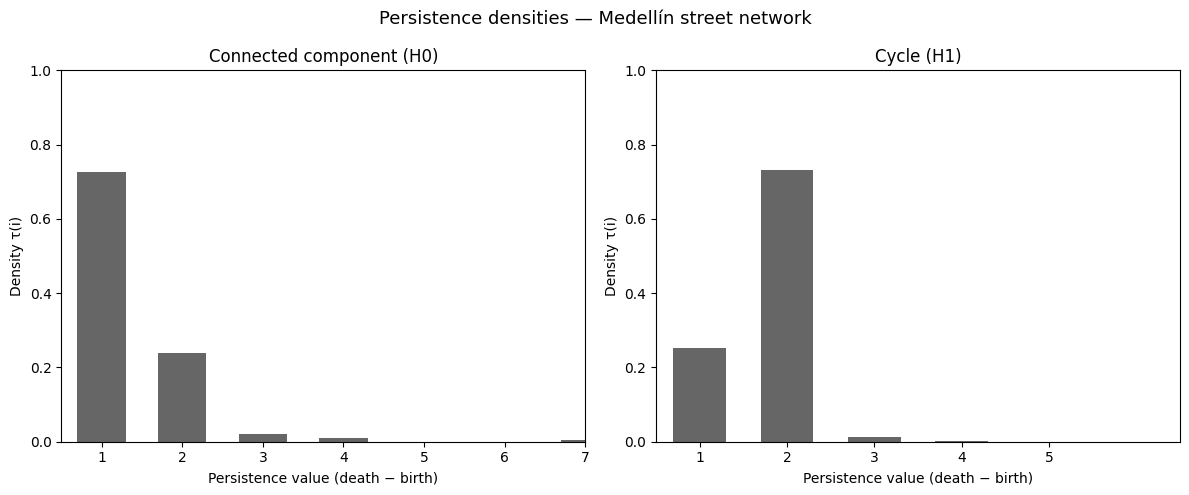

In [12]:
# -----------------------------
# PERSISTENCE DENSITY
# -----------------------------
def persistence_density(intervals, max_persistence=None):
    """
    Computes τ(i) = |{(p,q): (p,q) ∈ D, q-p = i}| / |D|
    for each integer persistence value i in [1, max_persistence].
    """
    finite = intervals[np.isfinite(intervals).all(axis=1)] if len(intervals) > 0 else np.empty((0, 2))
    if len(finite) == 0:
        return np.array([]), np.array([])

    lengths = (finite[:, 1] - finite[:, 0]).astype(int)
    total = len(finite)

    if max_persistence is None:
        max_persistence = int(lengths.max())
        print(max_persistence)

    i_values = np.arange(1, max_persistence + 1)
    density = np.array([np.sum(lengths == i) / total for i in i_values])
    return i_values, density


fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (intervals, label, dim) in zip(axes, [
    (h0, "Connected component (H0)", "H0"),
    (h1, "Cycle (H1)",               "H1"),
]):
    i_vals, dens = persistence_density(intervals, max_persistence=None)
    if len(i_vals) == 0:
        ax.set_title(f"No finite {dim} intervals")
        continue
    ax.bar(i_vals, dens, color="#666666", width=0.6)
    ax.set_xlim(0.5, len(lane_order) - 0.5)
    ax.set_ylim(0, 1.0)
    ax.set_xticks(i_vals)
    ax.set_xlabel("Persistence value (death − birth)")
    ax.set_ylabel("Density τ(i)")
    ax.set_title(label)

plt.suptitle("Persistence densities — Medellín street network", fontsize=13)
plt.tight_layout()
plt.show()


In [28]:

import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.patches as mpatches
import networkx as nx
import osmnx as ox

# High-contrast palette
DISTINCT_COMPONENT_COLORS = [
    "#0000ff", "#ff0000", "#00ff00", "#000033", "#ff00b6",
    "#005300", "#ffd300", "#009fff", "#9a4d42", "#00ffbe",
    "#783fc1", "#1f9698", "#f10dff", "#b1cc71", "#f1085c",
    "#fe8f42", "#dd00ff", "#201a01", "#720055", "#766c95",
]

def get_component_colors(n_components):
    if n_components <= len(DISTINCT_COMPONENT_COLORS):
        return DISTINCT_COMPONENT_COLORS[:n_components]
    fallback = cm.get_cmap("nipy_spectral", n_components)
    return [fallback(i) for i in range(n_components)]


def plot_connected_components_pdf(H, lane_values, filtration_time, filename, title):
    filename = Path(filename)
    filename.parent.mkdir(parents=True, exist_ok=True)
    max_step = max(filtration_time[lane] for lane in lane_values)
    edges_t = [
        (u, v) for u, v, d in H.edges(data=True)
        if d["filtration"] <= max_step
    ]

    G_t = nx.Graph()
    G_t.add_edges_from(edges_t)

    components = sorted(nx.connected_components(G_t), key=len, reverse=True)
    n_components = len(components)

    print(f"{filename}: {n_components} components, {G_t.number_of_nodes()} nodes, {G_t.number_of_edges()} edges")

    nodes_gdf = ox.graph_to_gdfs(G, edges=False)
    pos = {
        node: (nodes_gdf.loc[node, "x"], nodes_gdf.loc[node, "y"])
        for node in G_t.nodes() if node in nodes_gdf.index
    }

    fig, ax = plt.subplots(figsize=(15, 12))

    if n_components == 0:
        ax.set_axis_off()
        ax.set_title(title, fontsize=14)
    else:
        colors = get_component_colors(n_components)

        node_to_comp = {}
        legend_handles = []

        for idx, comp in enumerate(components):
            legend_handles.append(
                mpatches.Patch(
                    facecolor=colors[idx],
                    edgecolor="black",
                    label=f"Component {idx + 1} ({len(comp)} nodes)",
                )
            )
            for node in comp:
                node_to_comp[node] = idx

        valid_edges = [(u, v) for u, v in G_t.edges() if u in pos and v in pos]

        # --- SPLIT edges by component size ---
        large_edges = []
        small_edges = []

        for u, v in valid_edges:
            comp_idx = node_to_comp[u]
            comp_size = len(components[comp_idx])

            if comp_size <= 10:
                small_edges.append((u, v))
            else:
                large_edges.append((u, v))

        # --- DRAW LARGE components (background) ---
        nx.draw_networkx_edges(
            G_t,
            pos,
            edgelist=large_edges,
            ax=ax,
            edge_color=[colors[node_to_comp[u]] for u, v in large_edges],
            width=1.0,
            alpha=0.7
        )

        # --- DRAW SMALL components (highlighted) ---
        nx.draw_networkx_edges(
            G_t,
            pos,
            edgelist=small_edges,
            ax=ax,
            edge_color=[colors[node_to_comp[u]] for u, v in small_edges],
            width=1.0,
            alpha=1.0
        )

        # --- DRAW NODES for small components ---
        small_nodes = [
            n for comp in components if len(comp) <= 10
            for n in comp if n in pos
        ]

        nx.draw_networkx_nodes(
            G_t,
            pos,
            nodelist=small_nodes,
            node_size=0.1,
            node_color=[colors[node_to_comp[n]] for n in small_nodes],
            ax=ax
        )

        # --- TEXT ---
        ax.text(
            0.02, 0.98, f"Connected components: {n_components}",
            transform=ax.transAxes, ha="left", va="top", fontsize=11,
            bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="black", alpha=0.9),
        )

        # --- LEGEND ---
        ax.legend(
            handles=legend_handles,
            title="Colors used",
            loc="upper left",
            bbox_to_anchor=(1.02, 1.0),
            borderaxespad=0.0,
            frameon=True,
            fontsize=8,
            title_fontsize=10,
            ncol=1 if n_components <= 10 else 2,
        )

        fig.subplots_adjust(right=0.75)

    ax.set_aspect("equal")
    ax.set_axis_off()
    ax.set_title(title, fontsize=14)

    fig.savefig(filename, format="pdf", bbox_inches="tight")
    plt.close(fig)

    print(f"Saved: {filename}")


# ---- RUN ----
steps_dir = MDE_FIGS_DIR / "steps_mde"
steps_dir.mkdir(parents=True, exist_ok=True)

plot_connected_components_pdf(
    H, [max_lanes], filtration_time,
    steps_dir / f"step_00_{max_lanes}_lanes.pdf", f"{max_lanes} lanes - connected components"
)

plot_connected_components_pdf(
    H, lane_order, filtration_time,
    steps_dir / f"step_{len(lane_order)-1:02d}_{max_lanes}_to_1_lanes.pdf", f"{max_lanes} to 1 lanes - connected components"
)


steps_mde/step_00_trunk.pdf: 2 components, 244 nodes, 246 edges
Saved: steps_mde/step_00_trunk.pdf
steps_mde/step_05_trunk_primary_secondary_tertiary_unclassified_residential.pdf: 6 components, 15060 nodes, 21578 edges
Saved: steps_mde/step_05_trunk_primary_secondary_tertiary_unclassified_residential.pdf


In [ ]:
lane_order = list(range(max_lanes, 0, -1))
lane_order
